# Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import os
import seaborn as sns

from imblearn.over_sampling import SMOTE

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder

# Load Dataset

In [2]:
df = pd.read_csv('/Users/mansibmursalin/Library/CloudStorage/OneDrive-UniversityOfHouston/School-Work/University of Houston/5th Semester (Fall 2024)/INDE 6360/Project/Data/CVD.csv')
df.head(10)

,General_Health,Checkup,Exercise,Heart_Disease,Skin_Cancer,Other_Cancer,Depression,Diabetes,Arthritis,Sex,Age_Category,Height_(cm),Weight_(kg),BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
0,Poor,Within the past 2 years,No,No,No,No,No,No,Yes,Female,70-74,150.0,32.66,14.54,Yes,0.0,30.0,16.0,12.0
1,Very Good,Within the past year,No,Yes,No,No,No,Yes,No,Female,70-74,165.0,77.11,28.29,No,0.0,30.0,0.0,4.0
2,Very Good,Within the past year,Yes,No,No,No,No,Yes,No,Female,60-64,163.0,88.45,33.47,No,4.0,12.0,3.0,16.0
3,Poor,Within the past year,Yes,Yes,No,No,No,Yes,No,Male,75-79,180.0,93.44,28.73,No,0.0,30.0,30.0,8.0
4,Good,Within the past year,No,No,No,No,No,No,No,Male,80+,191.0,88.45,24.37,Yes,0.0,8.0,4.0,0.0
5,Good,Within the past year,No,No,No,No,Yes,No,Yes,Male,60-64,183.0,154.22,46.11,No,0.0,12.0,12.0,12.0
6,Fair,Within the past year,Yes,Yes,No,No,No,No,Yes,Male,60-64,175.0,69.85,22.74,Yes,0.0,16.0,8.0,0.0
7,Good,Within the past year,Yes,No,No,No,No,No,Yes,Female,65-69,165.0,108.86,39.94,Yes,3.0,30.0,8.0,8.0
8,Fair,Within the past year,No,No,No,No,Yes,No,No,Female,65-69,163.0,72.57,27.46,Yes,0.0,12.0,12.0,4.0
9,Fair,Within the past year,No,No,No,No,No,Yes,Yes,Female,70-74,163.0,91.63,34.67,No,0.0,12.0,12.0,1.0


Our Target Variable will be the Diabetes column

# Data Preprocessing

## Get Stats

In [3]:
df.describe()
# describe only shows statistics for the numerical variables and not for the categorical variables

,Height_(cm),Weight_(kg),BMI,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
count,308854.000000,308854.000000,308854.000000,308854.000000,308854.000000,308854.000000,308854.000000
mean,170.615249,83.588655,28.626211,5.096366,29.835200,15.110441,6.296616
std,10.658026,21.343210,6.522323,8.199763,24.875735,14.926238,8.582954
min,91.000000,24.950000,12.020000,0.000000,0.000000,0.000000,0.000000
25%,163.000000,68.040000,24.210000,0.000000,12.000000,4.000000,2.000000
50%,170.000000,81.650000,27.440000,1.000000,30.000000,12.000000,4.000000
75%,178.000000,95.250000,31.850000,6.000000,30.000000,20.000000,8.000000
max,241.000000,293.020000,99.330000,30.000000,120.000000,128.000000,128.000000


In [4]:
df.shape

(308854, 19)

308,854 rows and 19 columns

## Check for missing values

In [5]:
missing_values = df.isnull().sum()
print(missing_values)

General_Health                  0
Checkup                         0
Exercise                        0
Heart_Disease                   0
Skin_Cancer                     0
Other_Cancer                    0
Depression                      0
Diabetes                        0
Arthritis                       0
Sex                             0
Age_Category                    0
Height_(cm)                     0
Weight_(kg)                     0
BMI                             0
Smoking_History                 0
Alcohol_Consumption             0
Fruit_Consumption               0
Green_Vegetables_Consumption    0
FriedPotato_Consumption         0
dtype: int64


No missing values

## Check Categorical Values

In [6]:
categorical_columns = df.select_dtypes(include=['object', 'category']).columns
print(len(categorical_columns))
for col in categorical_columns:
    print(f"Distribution of '{col}':")
    print(df[col].value_counts())
    print("\n")

12
Distribution of 'General_Health':
General_Health
Very Good    110395
Good          95364
Excellent     55954
Fair          35810
Poor          11331
Name: count, dtype: int64


Distribution of 'Checkup':
Checkup
Within the past year       239371
Within the past 2 years     37213
Within the past 5 years     17442
5 or more years ago         13421
Never                        1407
Name: count, dtype: int64


Distribution of 'Exercise':
Exercise
Yes    239381
No      69473
Name: count, dtype: int64


Distribution of 'Heart_Disease':
Heart_Disease
No     283883
Yes     24971
Name: count, dtype: int64


Distribution of 'Skin_Cancer':
Skin_Cancer
No     278860
Yes     29994
Name: count, dtype: int64


Distribution of 'Other_Cancer':
Other_Cancer
No     278976
Yes     29878
Name: count, dtype: int64


Distribution of 'Depression':
Depression
No     246953
Yes     61901
Name: count, dtype: int64


Distribution of 'Diabetes':
Diabetes
No                                            259141
Yes 

## Check for Duplicate Values

In [7]:
#check duplicate values
df.duplicated().sum()

80

In [8]:
df = df.drop_duplicates()

In [9]:
df.shape

(308774, 19)

80 Duplicate Values removed

## Merge 4 classes into 2

In [10]:
df['Diabetes'] = df['Diabetes'].replace({
    'No, pre-diabetes or borderline diabetes': 'No',
    'Yes, but female told only during pregnancy': 'Yes'
})

# Check if the outcome variable is now binary
print(df['Diabetes'].value_counts()) 

Diabetes
No     265958
Yes     42816
Name: count, dtype: int64


## Encode Categorical Values

In [11]:
# Create a copy of the DataFrame to avoid modifying the original
df_encoded = df.copy()

# Create a label encoder object
label_encoder = LabelEncoder()

# Iterate through each object column and encode its values
for column in df_encoded.select_dtypes(include='object'):
    df_encoded[column] = label_encoder.fit_transform(df_encoded[column])

# Now, df_encoded contains the label-encoded categorical columns
df_encoded.head()

,General_Health,Checkup,Exercise,Heart_Disease,Skin_Cancer,Other_Cancer,Depression,Diabetes,Arthritis,Sex,Age_Category,Height_(cm),Weight_(kg),BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
0,3,2,0,0,0,0,0,0,1,0,10,150.0,32.66,14.54,1,0.0,30.0,16.0,12.0
1,4,4,0,1,0,0,0,1,0,0,10,165.0,77.11,28.29,0,0.0,30.0,0.0,4.0
2,4,4,1,0,0,0,0,1,0,0,8,163.0,88.45,33.47,0,4.0,12.0,3.0,16.0
3,3,4,1,1,0,0,0,1,0,1,11,180.0,93.44,28.73,0,0.0,30.0,30.0,8.0
4,2,4,0,0,0,0,0,0,0,1,12,191.0,88.45,24.37,1,0.0,8.0,4.0,0.0


## Check Correlation Matrix

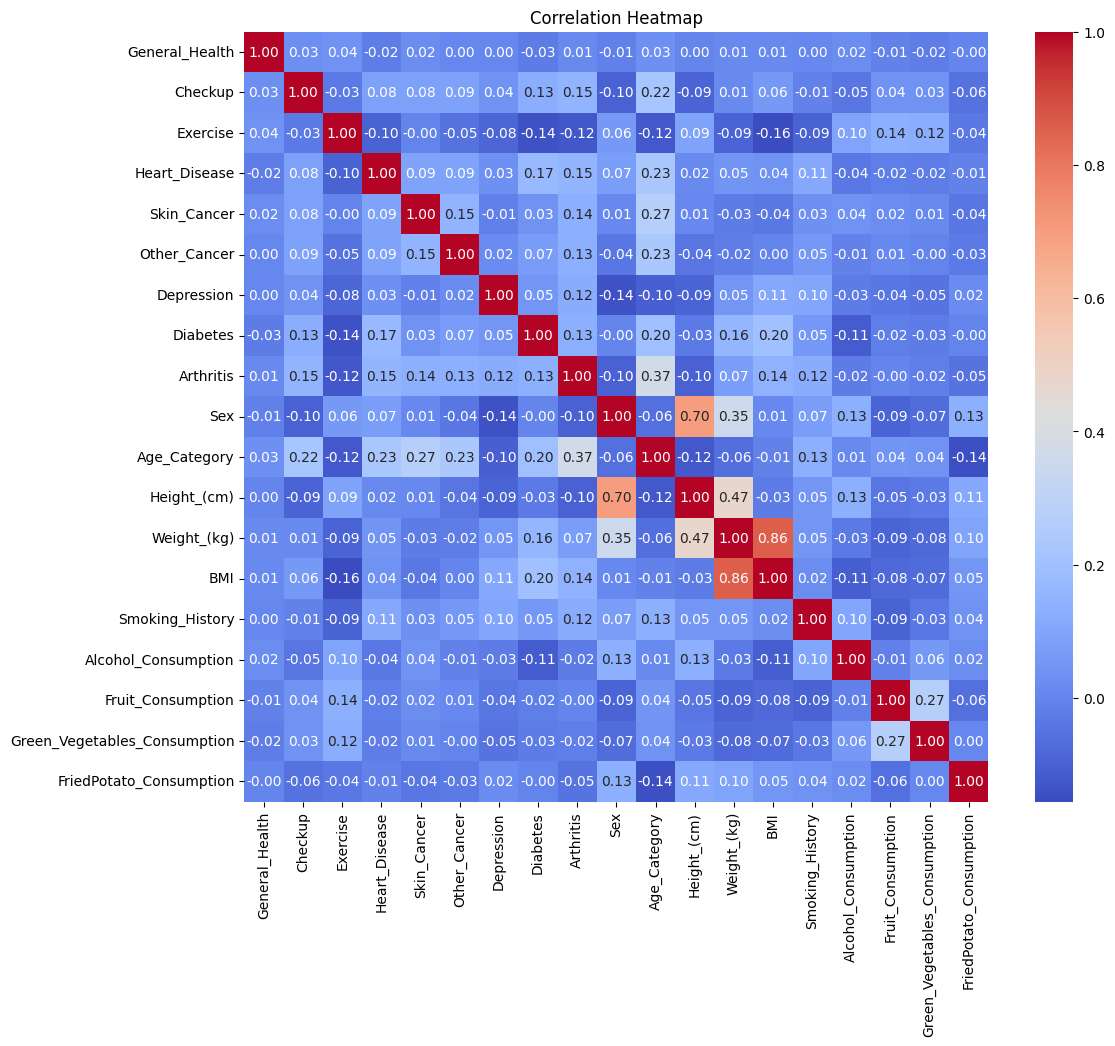

In [12]:
# Calculate the correlation matrix for Data
correlation_matrix = df_encoded.corr()

# Create a heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

There's a 70% correlation between Height and Sex, and 86% correlation between BMI and Weight

## Feature Selection: Drop Height and Weight as they have high correlation to Sex and BMI

In [13]:
# Assuming df is your DataFrame
df_encoded = df_encoded.drop(['Height_(cm)', 'Weight_(kg)'], axis=1)

print(df_encoded.columns)

Index(['General_Health', 'Checkup', 'Exercise', 'Heart_Disease', 'Skin_Cancer',
       'Other_Cancer', 'Depression', 'Diabetes', 'Arthritis', 'Sex',
       'Age_Category', 'BMI', 'Smoking_History', 'Alcohol_Consumption',
       'Fruit_Consumption', 'Green_Vegetables_Consumption',
       'FriedPotato_Consumption'],
      dtype='object')


## Deal with Outliers

In [14]:
# Define the columns to remove outliers (numerical value columns)
selected_columns = ['BMI', 'Alcohol_Consumption', 
                    'Fruit_Consumption', 'Green_Vegetables_Consumption', 'FriedPotato_Consumption']

# Calculate the IQR for the selected columns in the training data
Q1 = df_encoded[selected_columns].quantile(0.25)
Q3 = df_encoded[selected_columns].quantile(0.75)
IQR = Q3 - Q1

# SetTING a threshold value for outlier detection (e.g., 1.5 times the IQR)
threshold = 3

# CreatING a mask for outliers in the selected columns
outlier_mask = (
    (df_encoded[selected_columns] < (Q1 - threshold * IQR)) |
    (df_encoded[selected_columns] > (Q3 + threshold * IQR))
).any(axis=1)

# Remove rows with outliers from X_train and y_train
df_encoded_cleaned = df_encoded[~outlier_mask]

# Print the number of rows removed
num_rows_removed = len(df_encoded) - len(df_encoded_cleaned)
print(f"Number of rows removed due to outliers: {num_rows_removed}")

Number of rows removed due to outliers: 52243


## Visualization

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


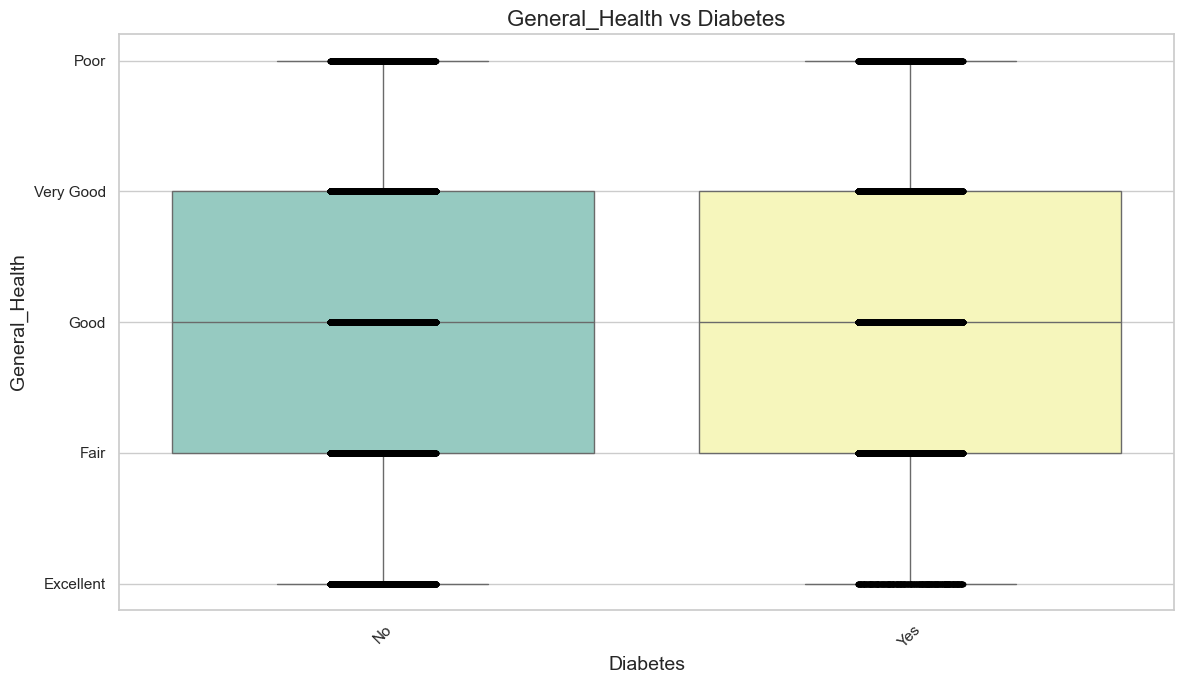

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


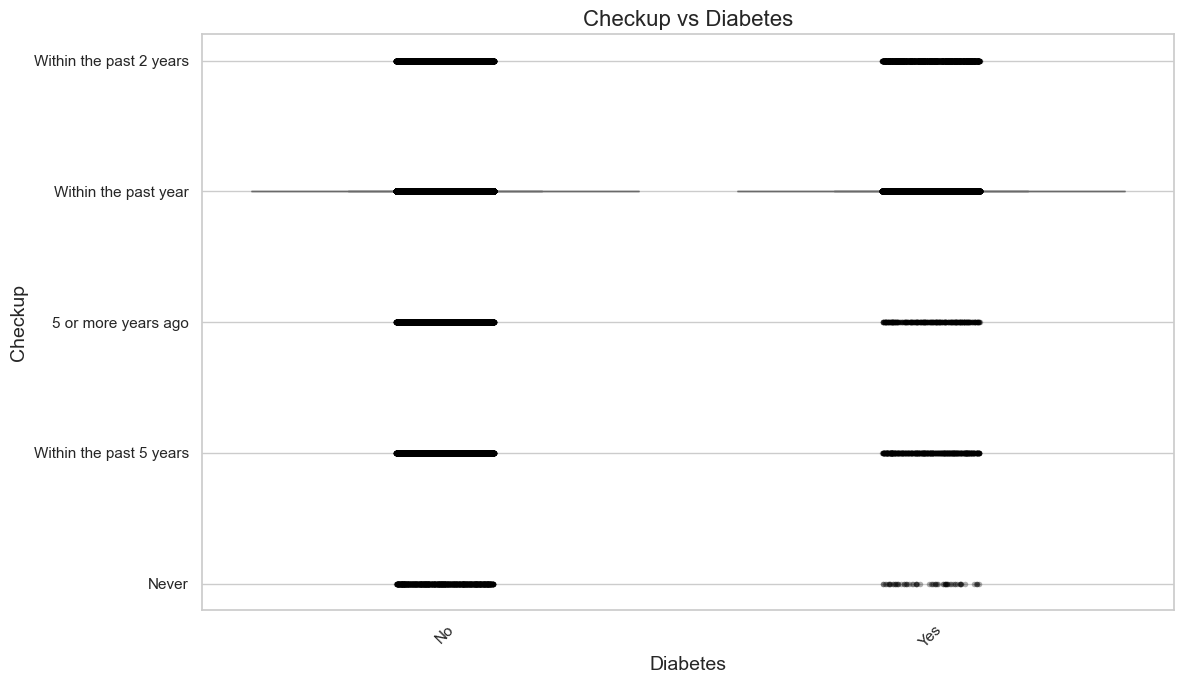

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


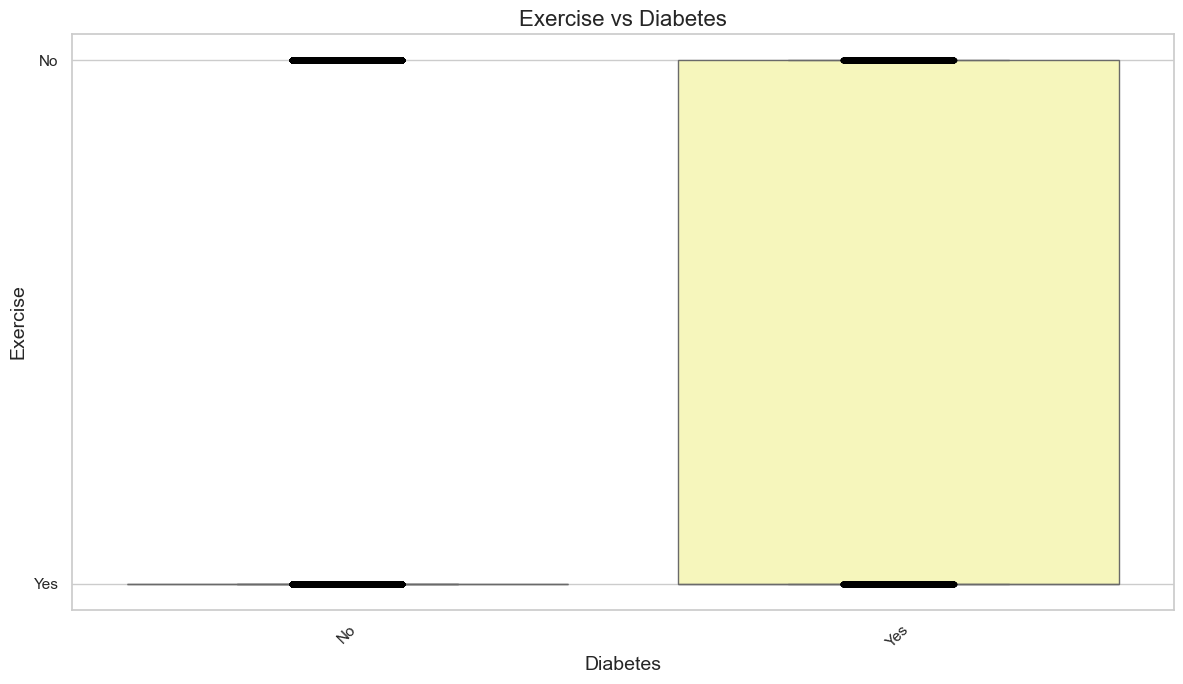

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


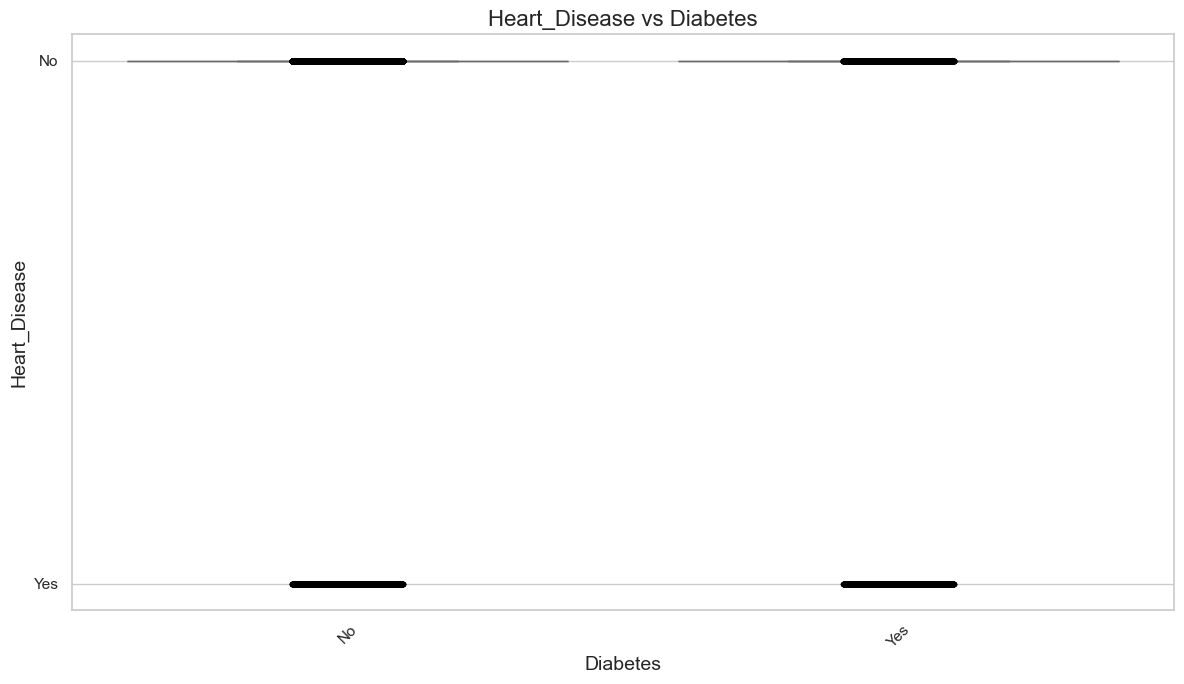

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


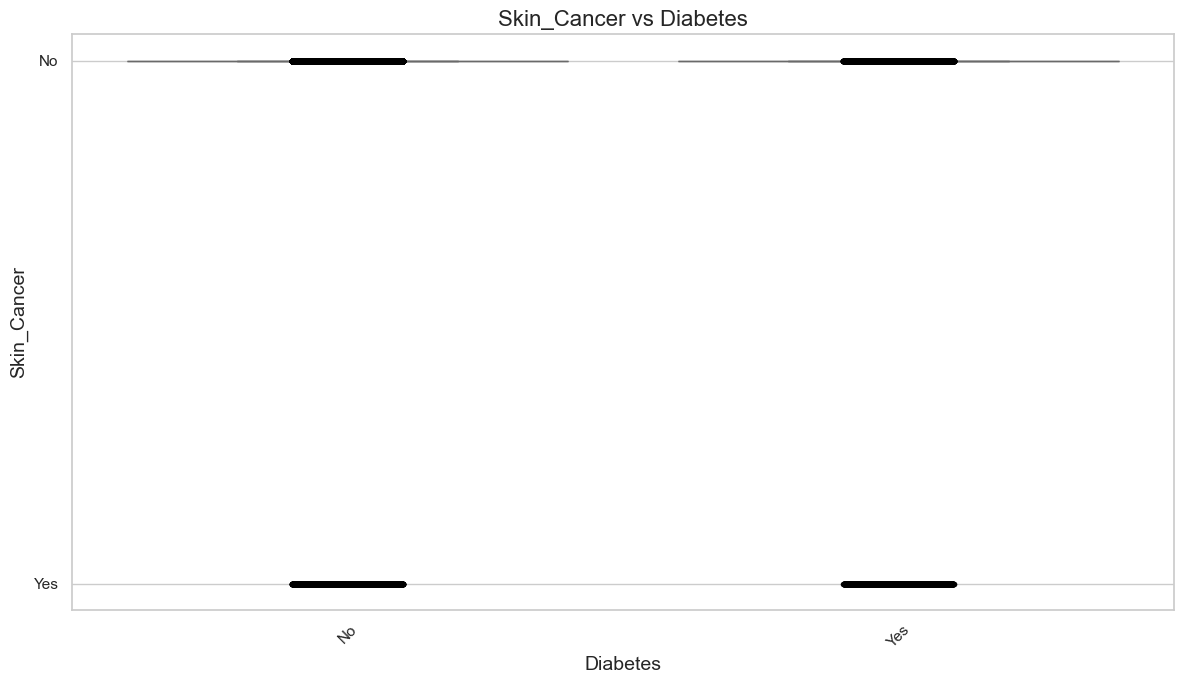

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


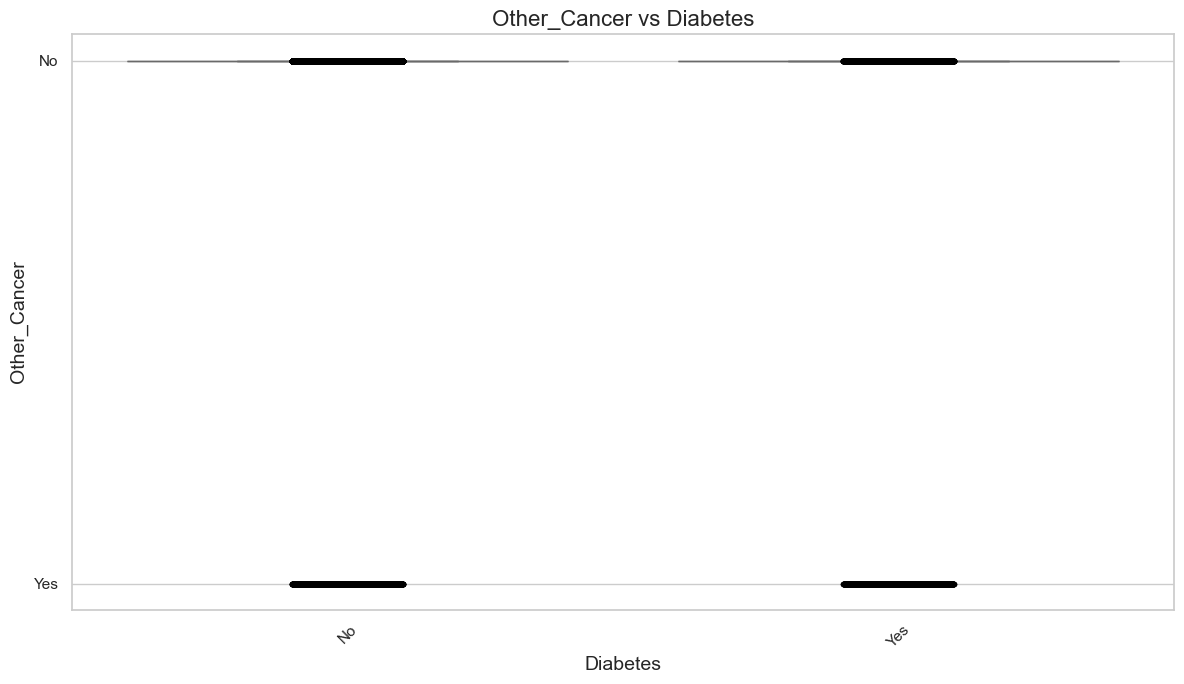

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


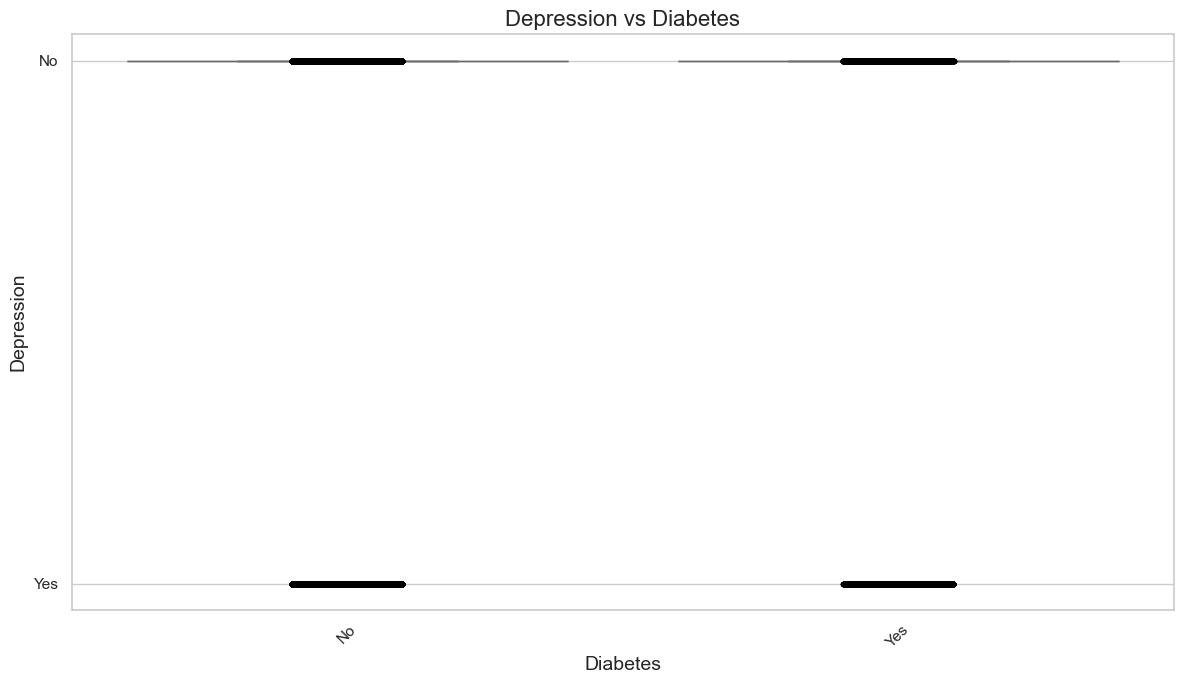

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


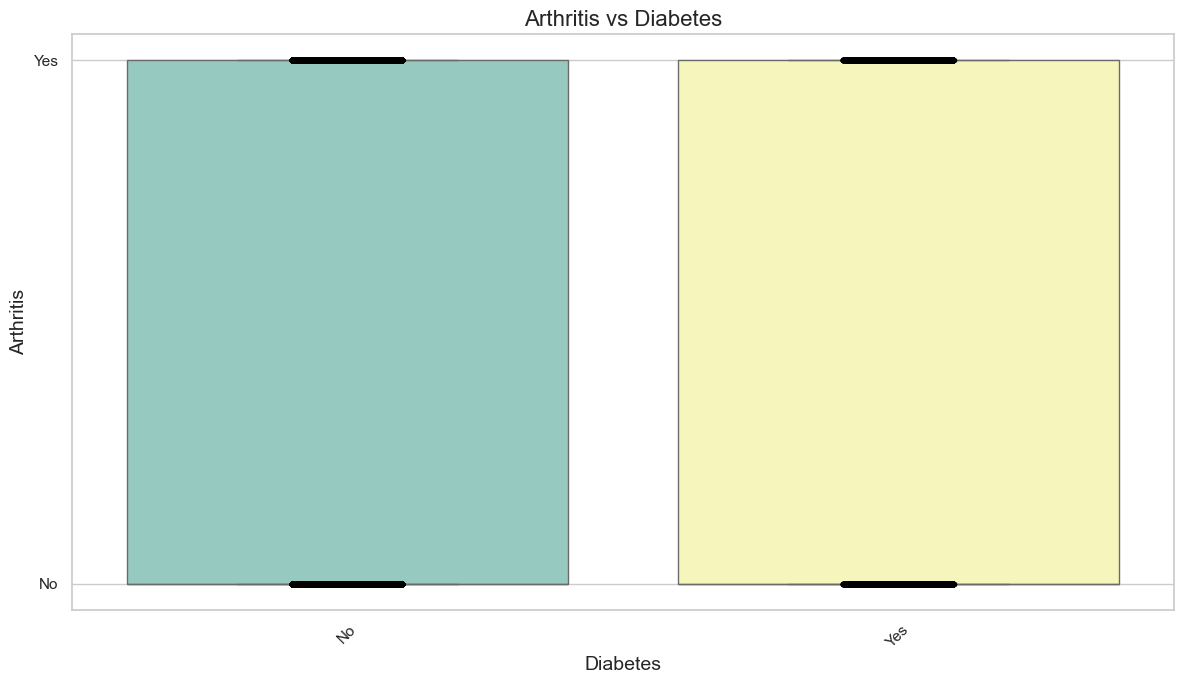

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


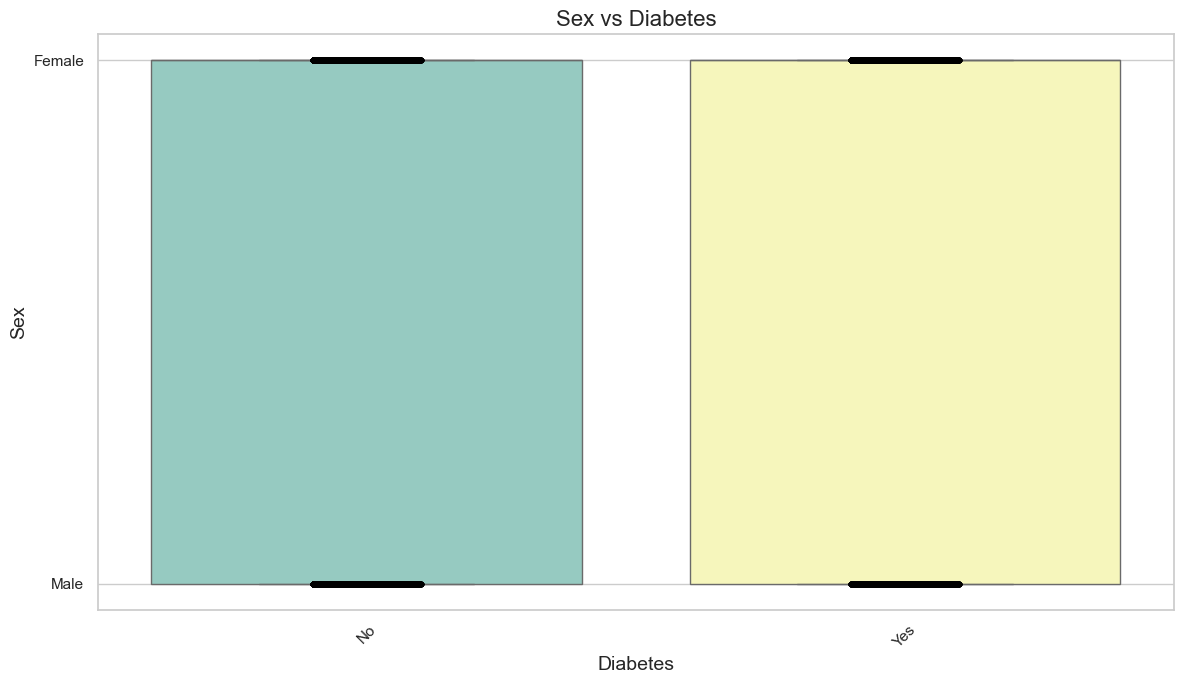

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


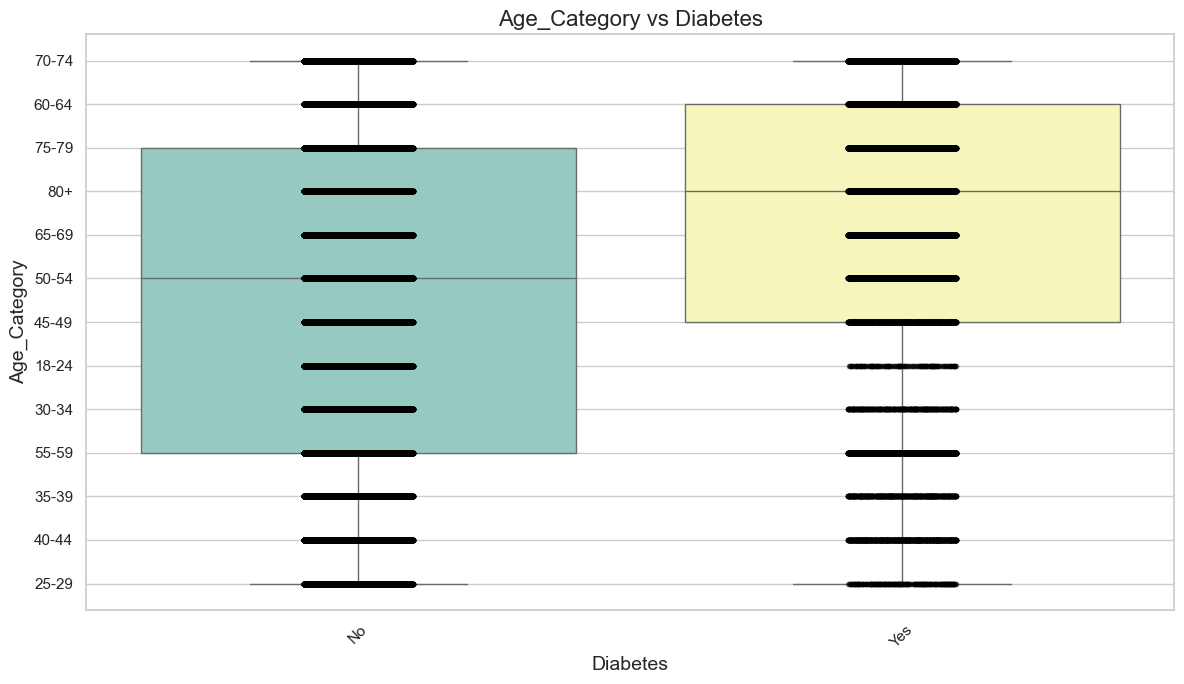

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


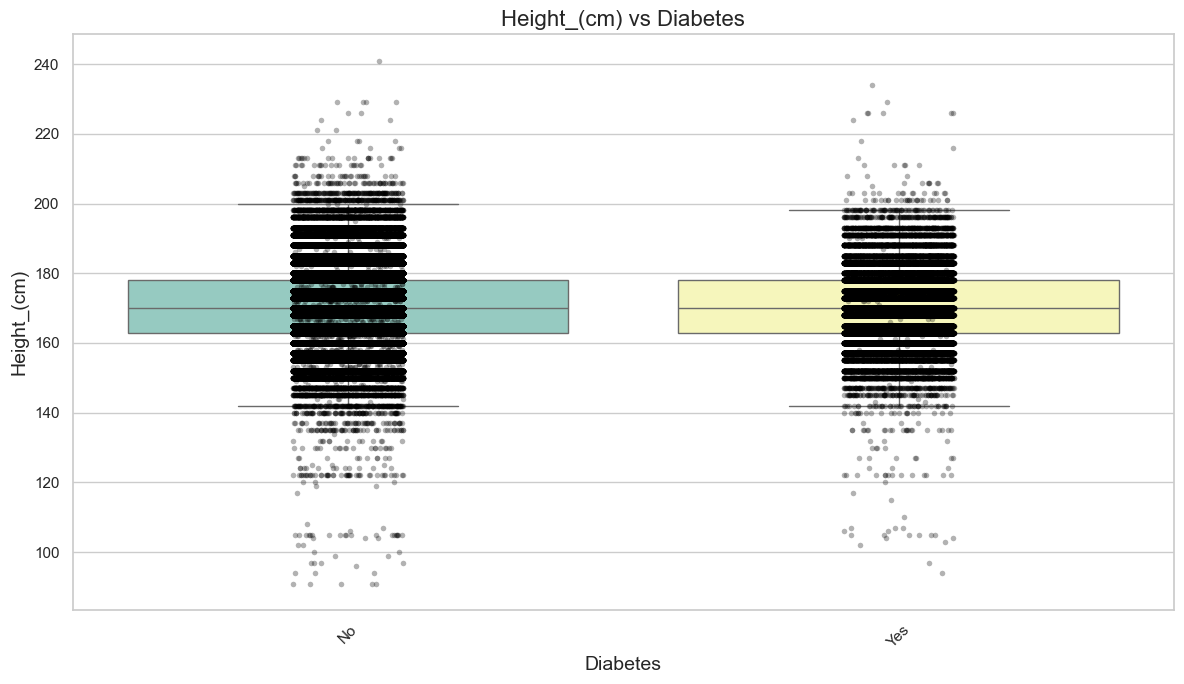

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


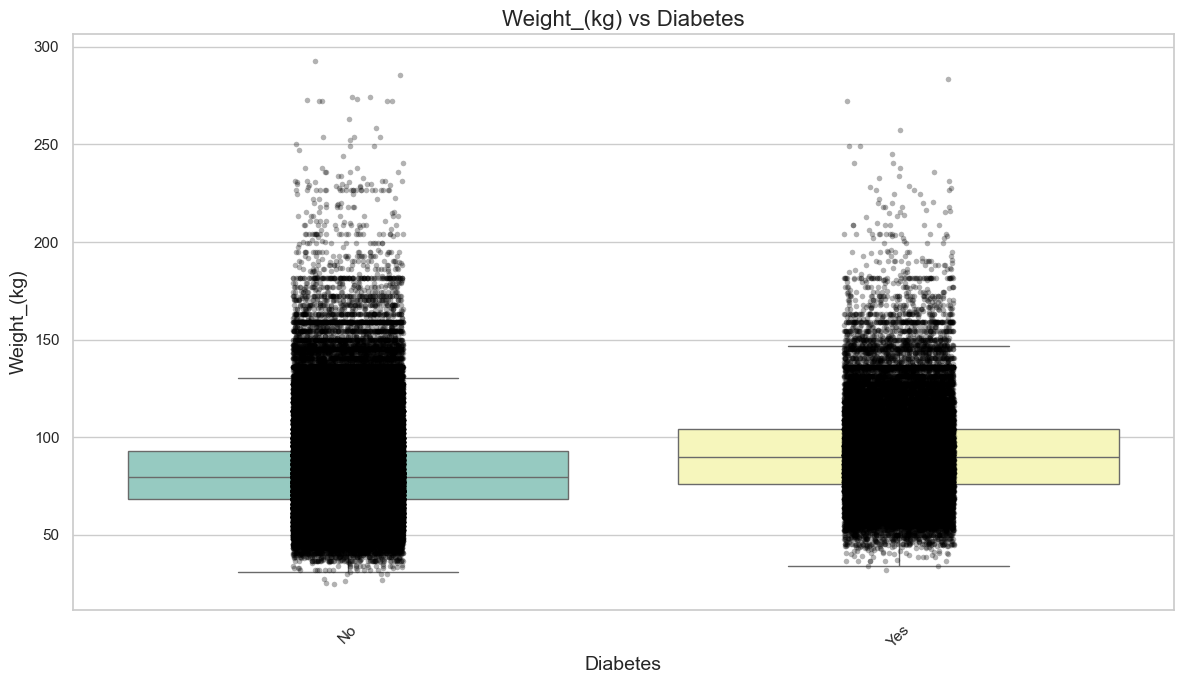

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


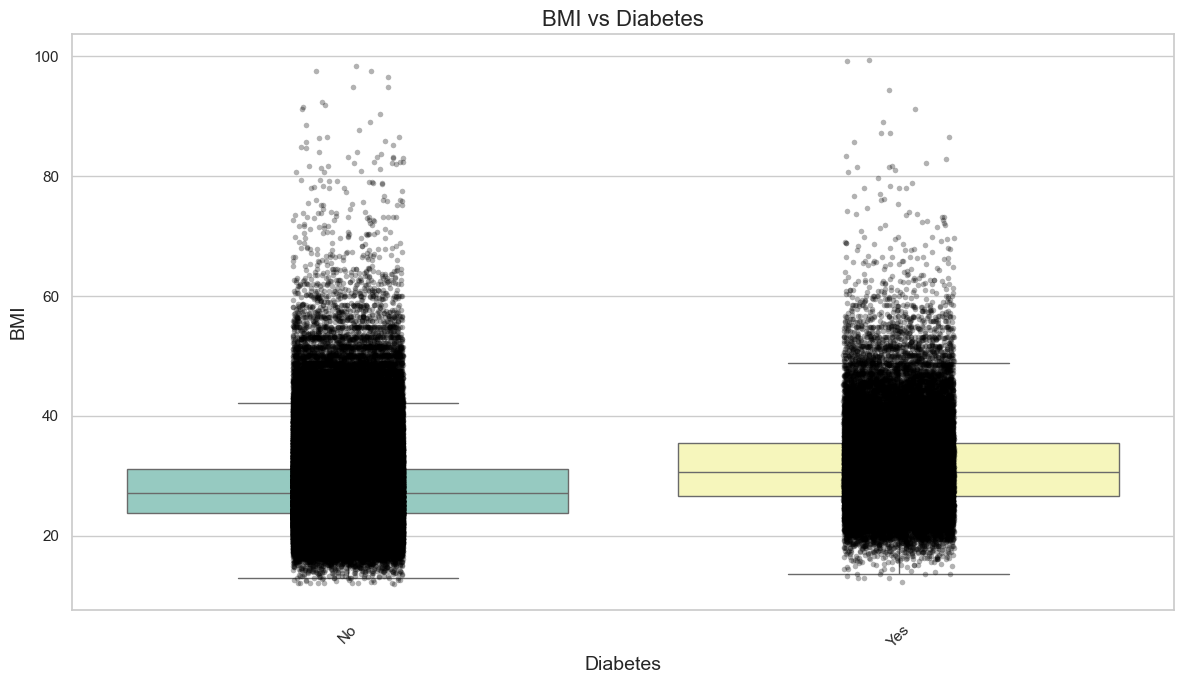

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


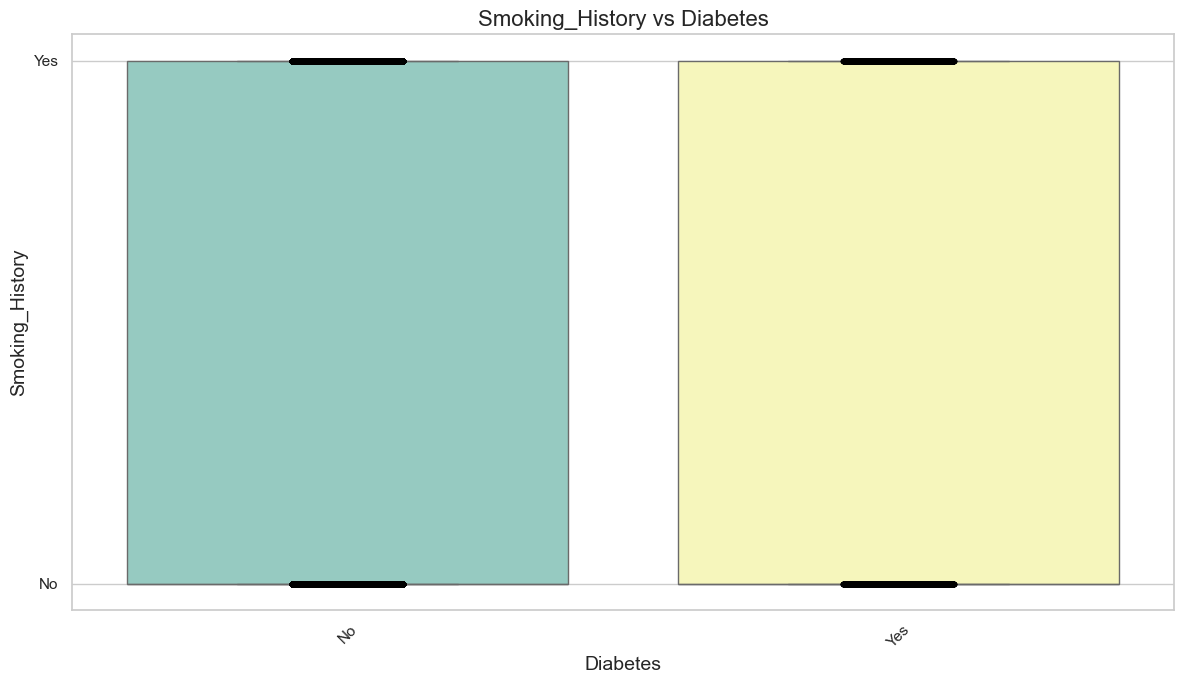

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


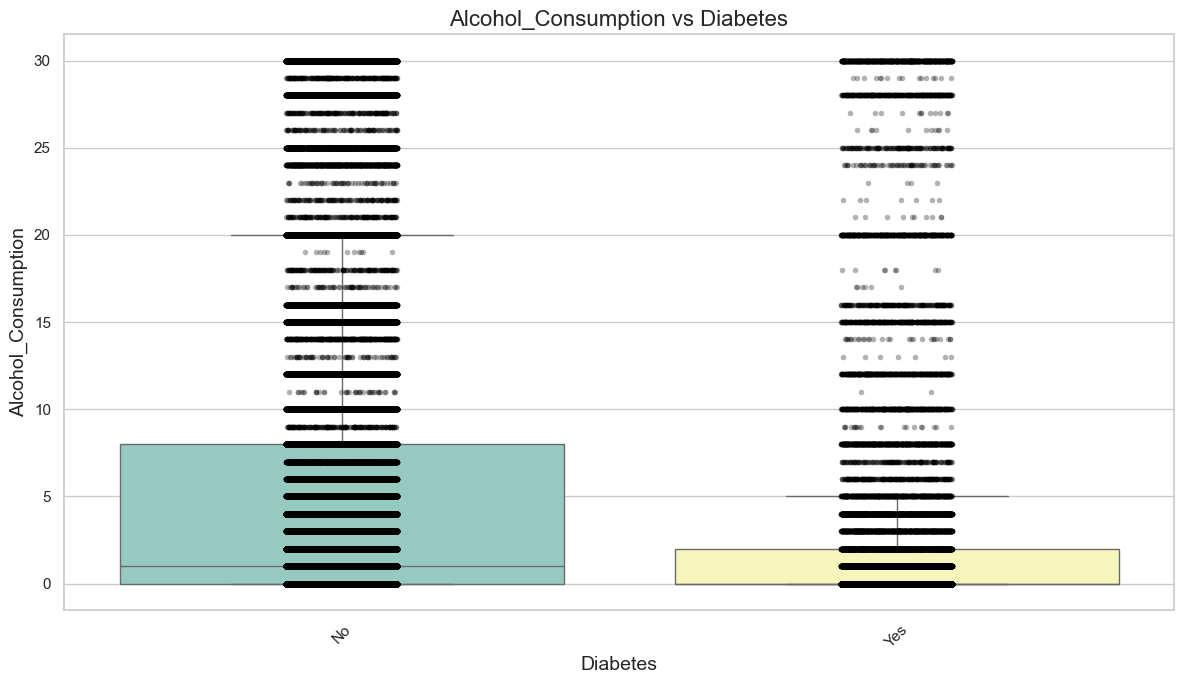

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


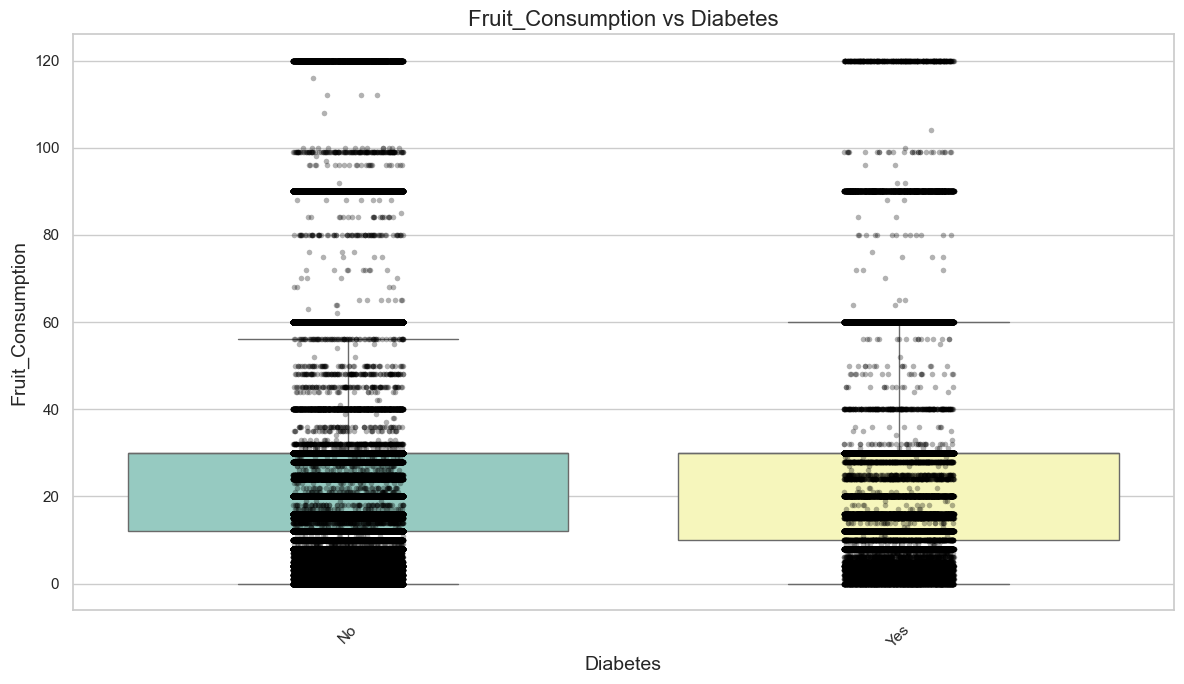

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


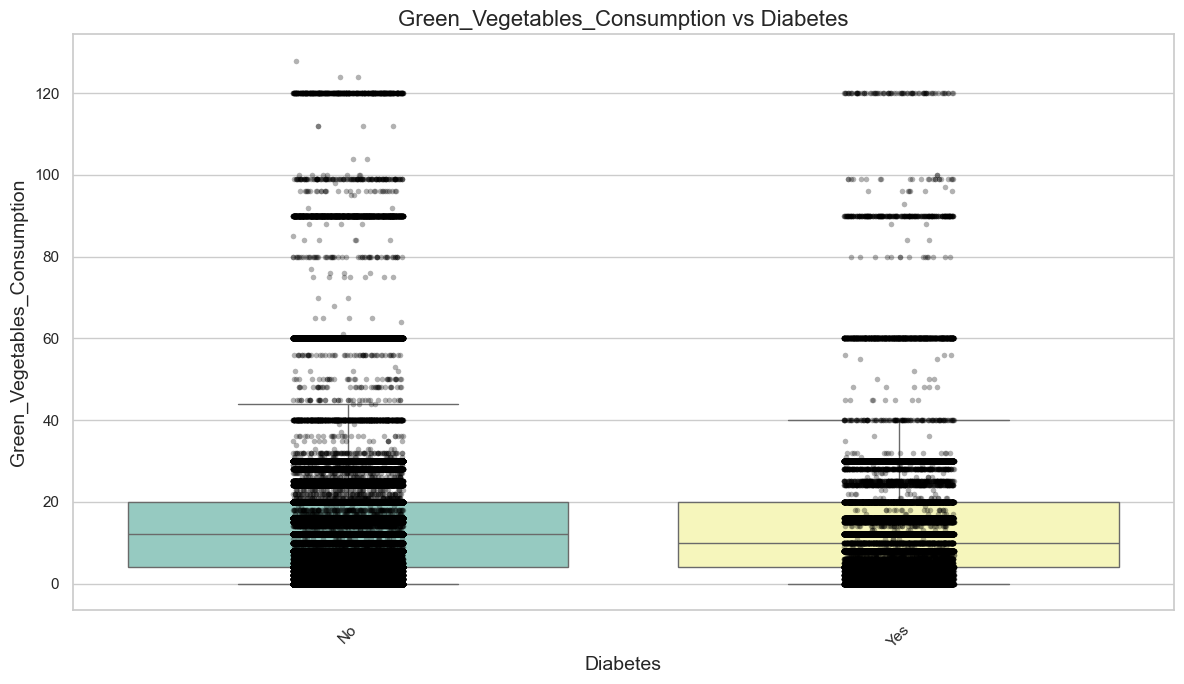

/var/folders/3z/wrv11djn743827h4nz7rqkbm0000gn/T/ipykernel_6445/36213175.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


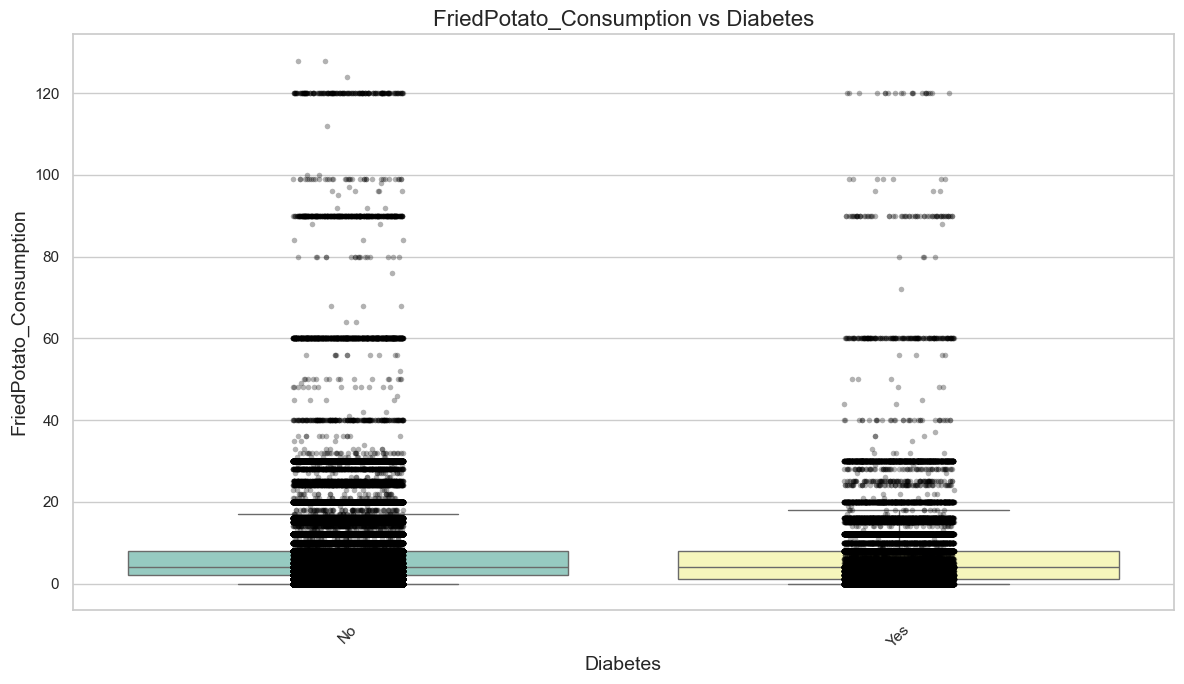

In [15]:
target_column = 'Diabetes'  # Replace 'Diabetes' with the actual column name if different
feature_columns = [col for col in df.columns if col != target_column]

# Set a Seaborn style for better aesthetics
sns.set(style="whitegrid")

# Generate box plots with enhanced visualizations
for feature in feature_columns:
    plt.figure(figsize=(12, 7))  # Larger plot for better readability
    sns.boxplot(
        x=target_column,
        y=feature,
        data=df,
        palette='Set3',  # Use a color palette for better contrast
        showfliers=False  # Optionally hide outliers for a clearer plot
    )
    sns.stripplot(
        x=target_column,
        y=feature,
        data=df,
        color='black',
        alpha=0.3,
        jitter=True,
        size=4
    )
    plt.title(f'{feature} vs {target_column}', fontsize=16)
    plt.xlabel(target_column, fontsize=14)
    plt.ylabel(feature, fontsize=14)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

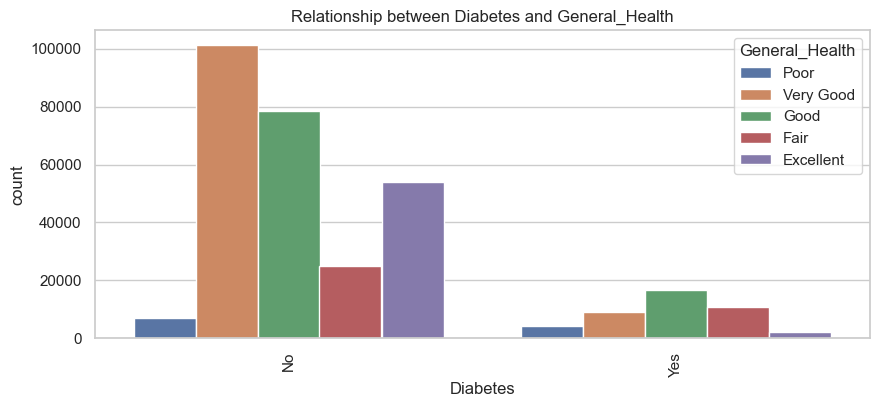

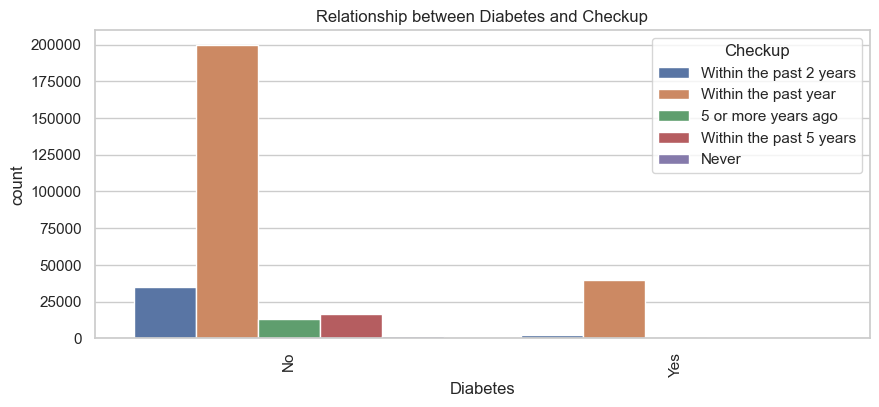

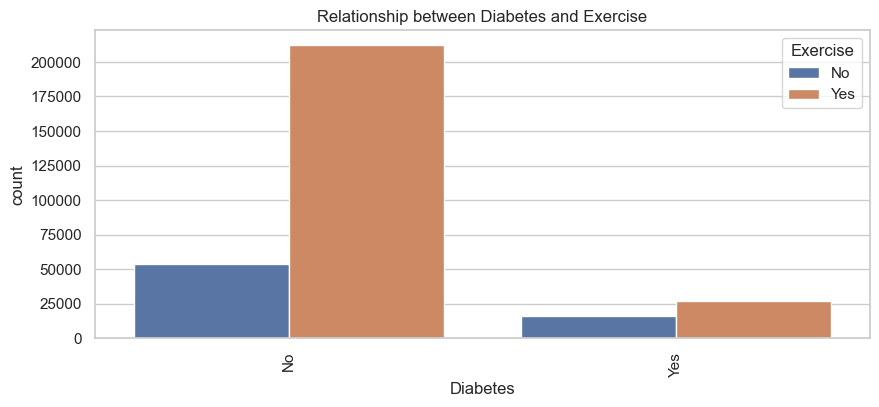

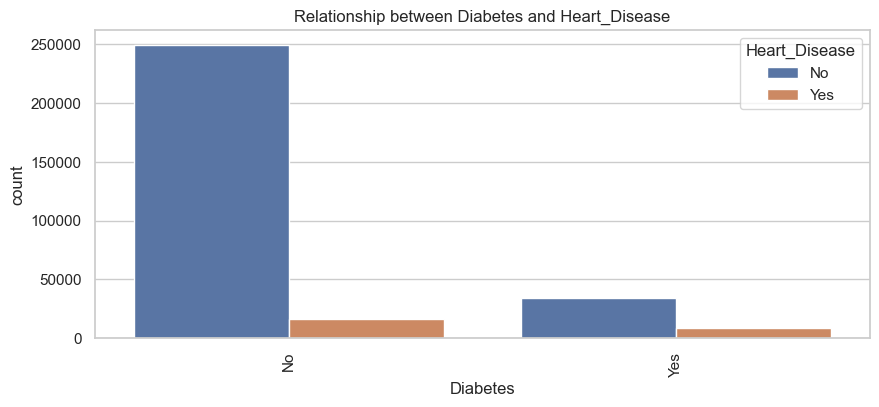

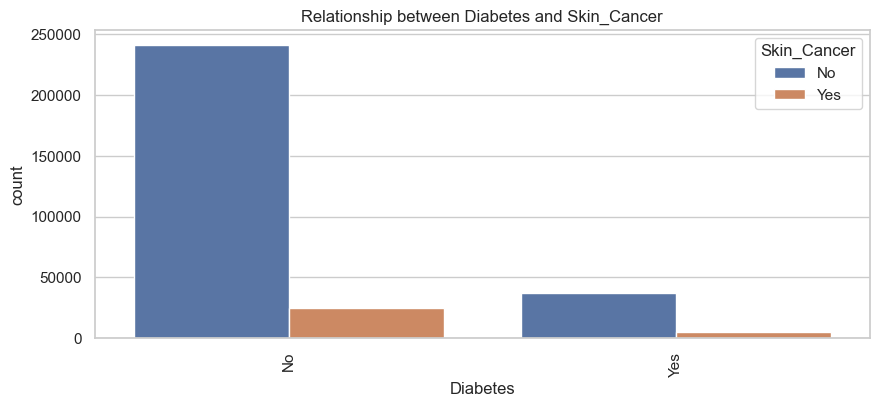

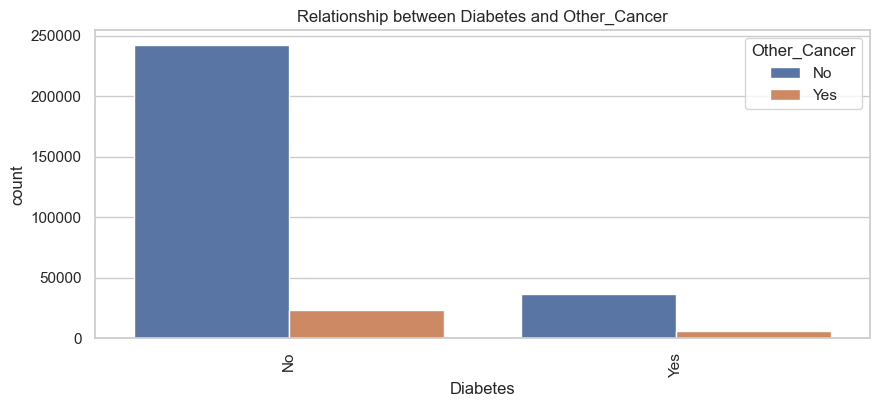

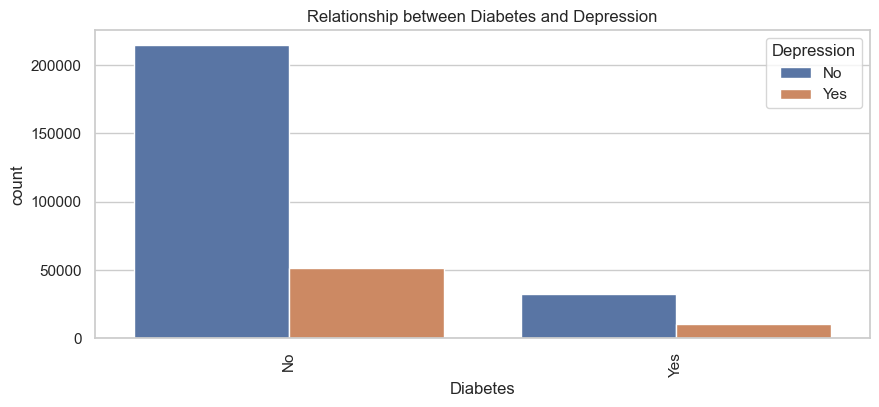

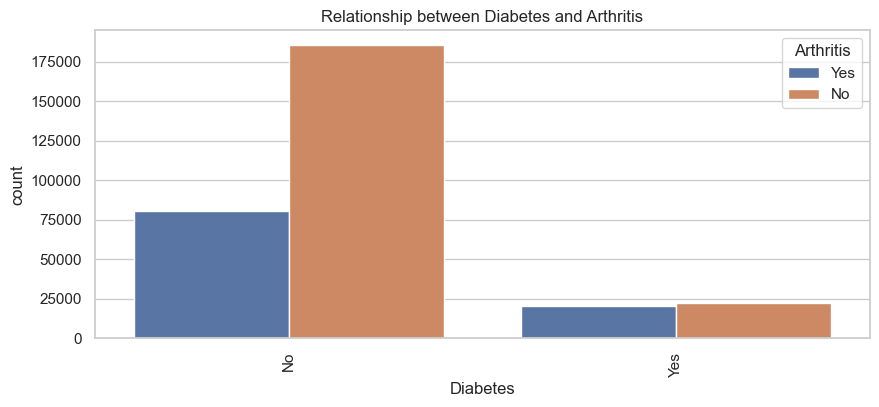

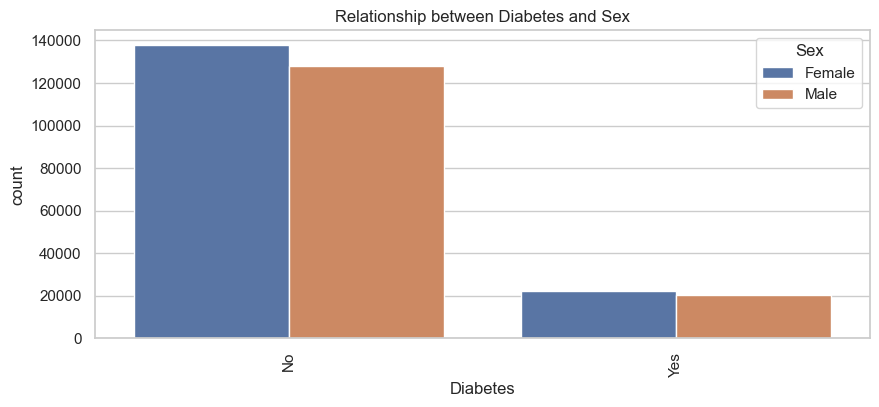

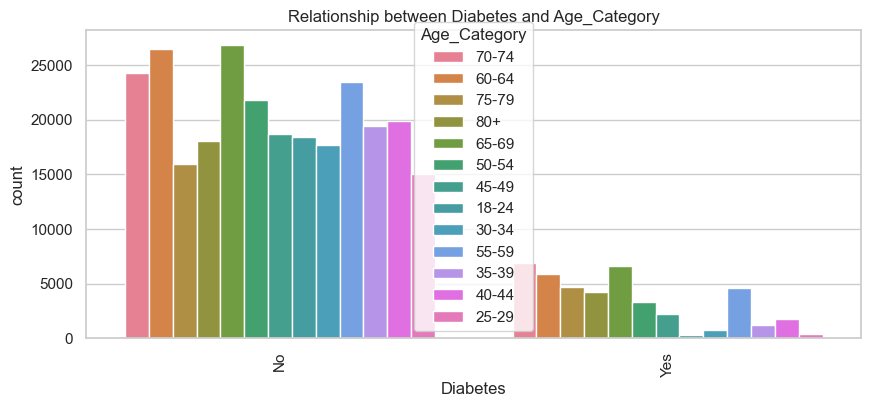

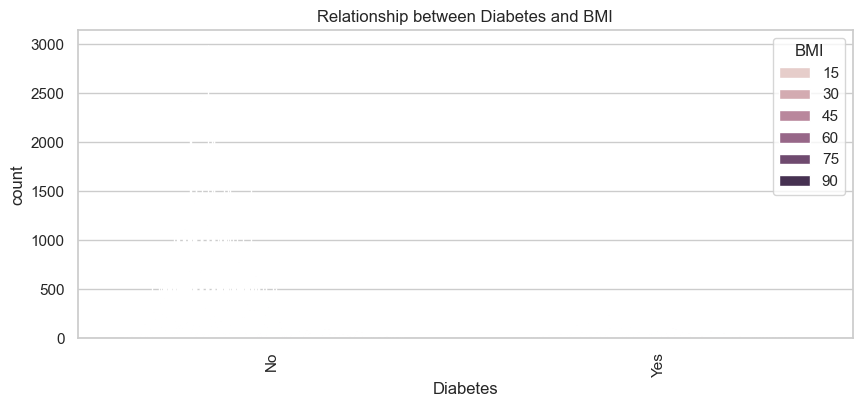

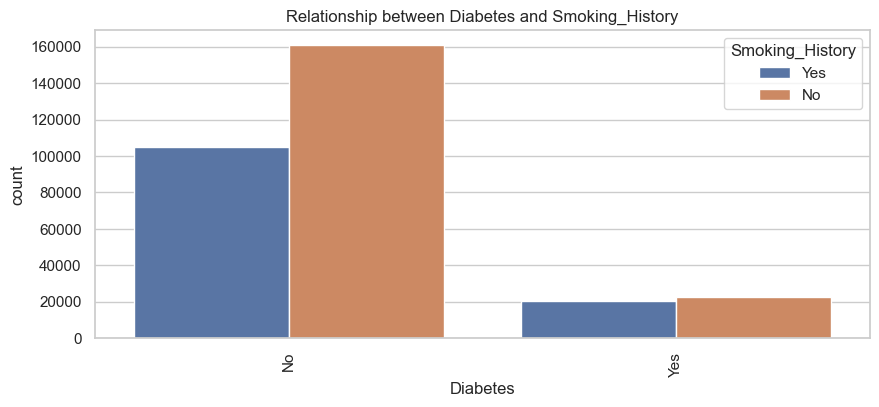

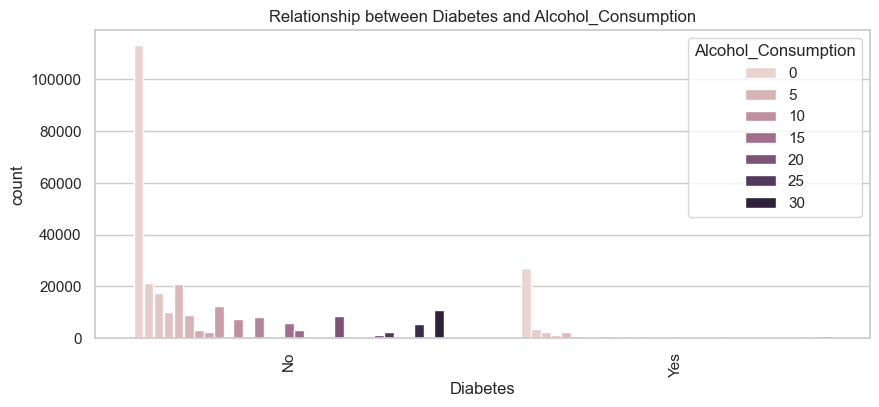

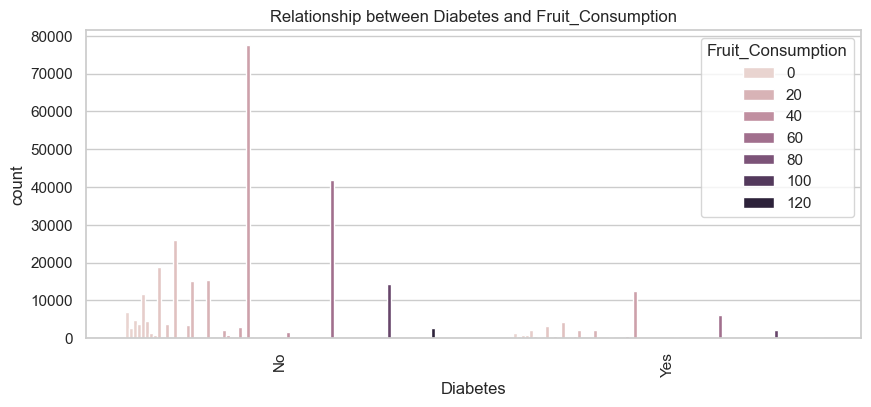

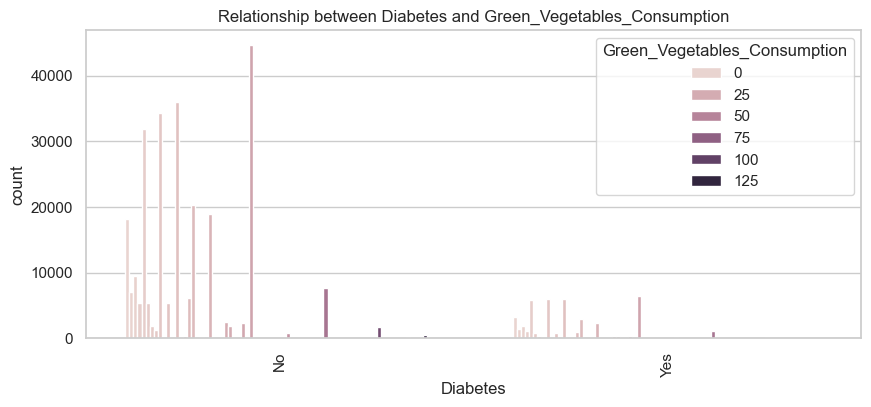

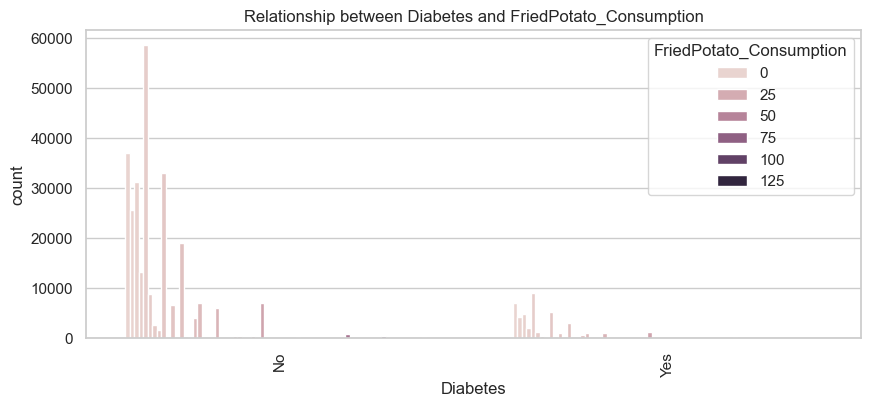

In [16]:
selected_variables = 'Diabetes'  # Replace 'Diabetes' with the actual column name if different
disease_conditions = [col for col in df_encoded.columns if col != target_column]

for disease in disease_conditions:
        plt.figure(figsize=(10, 4))
        sns.countplot(data=df, x='Diabetes', hue=disease)
        plt.title('Relationship between ' + 'Diabetes' + ' and ' + disease)
        plt.xticks(rotation=90)
        plt.show()

## Divide Dataset to Train and Test Sets and Scale Them


In [17]:
X = df_encoded.drop("Diabetes", axis = 1)
y = df_encoded['Diabetes']

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Example dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize the scaler
scaler = StandardScaler()

# Fit the scaler on the training data
scaler.fit(X_train)

# Transform both train and test sets
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

## Deal with Class Imbalance with SMOTE


In [19]:
#CHECK THE CLASS VARIABLE
y_train.value_counts()

Diabetes
0    186130
1     30011
Name: count, dtype: int64

In [20]:
smote = SMOTE(random_state=42)
X_train_scaled_balanced, y_train_balanced = smote.fit_resample(X_train_scaled_df, y_train)

In [21]:
y_train_balanced.value_counts()

Diabetes
0    186130
1    186130
Name: count, dtype: int64

In [22]:
y_test.value_counts()

Diabetes
0    79828
1    12805
Name: count, dtype: int64

In [23]:
X_train_scaled_balanced.head()

,General_Health,Checkup,Exercise,Heart_Disease,Skin_Cancer,Other_Cancer,Depression,Arthritis,Sex,Age_Category,BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
0,0.487756,0.476029,0.54024,3.375623,3.055121,3.055444,1.993437,1.437421,-0.963170,0.699407,-0.223321,1.211069,-0.501129,-0.556653,-0.209552,2.525462
1,-0.181217,0.476029,0.54024,-0.296242,-0.327319,3.055444,-0.501646,-0.695691,-0.963170,0.699407,-0.369131,-0.825717,-0.622927,0.006160,-1.014403,-0.733196
2,1.156730,0.476029,0.54024,-0.296242,-0.327319,-0.327285,-0.501646,-0.695691,1.038239,-0.151524,0.452009,1.211069,0.838653,0.006160,-0.209552,-0.500434
3,1.156730,0.476029,0.54024,-0.296242,3.055121,-0.327285,-0.501646,1.437421,1.038239,0.132119,0.227922,1.211069,0.351459,1.212188,-0.477836,0.197849
4,-0.181217,0.476029,0.54024,-0.296242,3.055121,3.055444,-0.501646,1.437421,1.038239,1.550338,-0.448942,-0.825717,-0.622927,-0.395850,-0.746120,-0.267673


In [24]:
X_test_scaled_df

,General_Health,Checkup,Exercise,Heart_Disease,Skin_Cancer,Other_Cancer,Depression,Arthritis,Sex,Age_Category,BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
112130,-1.519163,-0.504216,0.54024,-0.296242,-0.327319,-0.327285,-0.501646,-0.695691,-0.963170,0.132119,-0.863349,1.211069,-0.622927,-0.395850,-0.746120,1.128895
95666,1.156730,0.476029,0.54024,3.375623,-0.327319,-0.327285,-0.501646,1.437421,-0.963170,0.983051,0.304664,1.211069,-0.622927,0.006160,1.668433,-0.733196
206006,-1.519163,0.476029,0.54024,-0.296242,-0.327319,-0.327285,-0.501646,-0.695691,-0.963170,-0.151524,-1.268547,-0.825717,-0.622927,0.006160,0.997724,-0.733196
280617,1.156730,0.476029,0.54024,-0.296242,-0.327319,-0.327285,-0.501646,-0.695691,-0.963170,1.550338,-0.323086,-0.825717,-0.622927,1.212188,-0.746120,-0.384054
148564,1.156730,0.476029,0.54024,-0.296242,-0.327319,-0.327285,-0.501646,-0.695691,-0.963170,1.266694,0.364523,-0.825717,-0.379331,0.006160,0.058731,0.081469
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34846,-1.519163,0.476029,0.54024,-0.296242,-0.327319,-0.327285,-0.501646,-0.695691,1.038239,0.415763,0.587074,-0.825717,1.204048,0.006160,0.327015,-0.384054
254616,1.156730,0.476029,0.54024,-0.296242,-0.327319,-0.327285,-0.501646,1.437421,-0.963170,0.699407,-0.646937,1.211069,-0.379331,0.006160,-0.209552,-0.500434
146276,1.156730,0.476029,0.54024,-0.296242,-0.327319,-0.327285,-0.501646,-0.695691,-0.963170,-1.002456,-0.573264,1.211069,-0.622927,0.006160,0.997724,0.197849
293271,-0.181217,0.476029,0.54024,-0.296242,-0.327319,-0.327285,-0.501646,1.437421,-0.963170,-0.718812,0.745163,1.211069,-0.622927,0.006160,3.009851,-0.267673


All classes are balanced

## Save the files

In [25]:
pd.DataFrame(X_train_scaled_balanced).to_csv('/Users/mansibmursalin/Library/CloudStorage/OneDrive-UniversityOfHouston/School-Work/University of Houston/5th Semester (Fall 2024)/INDE 6360/Project/Data/X_train_scaled_balanced.csv', index=False)
pd.DataFrame(y_train_balanced).to_csv('/Users/mansibmursalin/Library/CloudStorage/OneDrive-UniversityOfHouston/School-Work/University of Houston/5th Semester (Fall 2024)/INDE 6360/Project/Data/y_train_balanced.csv', index=False)

# Save the test data
pd.DataFrame(X_test_scaled_df).to_csv('/Users/mansibmursalin/Library/CloudStorage/OneDrive-UniversityOfHouston/School-Work/University of Houston/5th Semester (Fall 2024)/INDE 6360/Project/Data/X_test_scaled.csv', index=False)
pd.DataFrame(y_test).to_csv('/Users/mansibmursalin/Library/CloudStorage/OneDrive-UniversityOfHouston/School-Work/University of Houston/5th Semester (Fall 2024)/INDE 6360/Project/Data/y_test.csv', index=False)

print("All files have been saved as CSVs.")

All files have been saved as CSVs.
